In [1]:
import numpy as np
# import ds_format as ds
import os
import glob
# import aquarius_time as aq
import xarray as xr
from scipy import interpolate
from netCDF4 import Dataset
from datetime import datetime
import pandas as pd
import time

data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'

amps_dir = data_dir + '/AMPS_NC/'
mpl2nc_dir = data_dir + '/CHCH_preprocessed/mpl2nc{}/'

alcf_dir = data_dir + '/CHCH_preprocessed/alcf{}/lidar/'

output_dir = data_dir + '/CHCH_v4_reference/preprocessed{}/'

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning) 

### Opening MPL

In [2]:
def getDropVars():
    date = '20210518'
    path = (mpl2nc_dir+'{}1200.nc').format(date[:-2],date)
    
    d = xr.open_dataset(path)
    drop_vars = [i for i in d.data_vars if i not in ['nrb_crosspol', 'nrb_copol', 'c', 'bin_time', 'range', 'time']]
    d.close()

    return drop_vars

In [3]:
def getMPL(date, drop_vars):

    filepath = (mpl2nc_dir+'{}*').format(date[:-2],date)
    ds = xr.open_mfdataset(filepath,combine='nested',concat_dim='profile', drop_variables = drop_vars)
        
    nrb_cross_pol = ds['nrb_crosspol']
    nrb_co_pol = ds['nrb_copol']
    time = ds['time']

    c = ds['c'][0]
    bin_time= ds['bin_time'][0]
    range_ = ds['range']

    height = 0.5*bin_time*c*(range_+0.5)

    ds.close()

    new_ds = xr.Dataset({'nrb_cross_pol':nrb_cross_pol,'nrb_co_pol':nrb_co_pol}, coords = {'time':time, 'height':height})

    return new_ds


### Opening AMPS

In [4]:
def pres2alt(pres):
    """
    pressure: units hPa
    alt: units m
    """
    
    scale_height = 7000# use tsurface
    sfc_press = 1013
    
    alt = -scale_height*np.log(pres/sfc_press)
    return alt#.replace([np.inf, -np.inf], np.nan).dropna()

def openAMPS(date):
    ### Opens AMPS

    amps_filepath= amps_dir+"{0}00/{0}00_WRF_NZ_f*.nc".format(date)
    amps_ds = xr.open_mfdataset(amps_filepath,combine='nested',concat_dim='time',drop_variables=['A_PCP_GDS5_SFC_acc3h','A_PCP_GDS5_SFC_acc'])
    
    temps=amps_ds.variables['TMP_GDS5_ISBL'] #temp as function of pressure level (altitude)
    iso_lvls=amps_ds.variables['lv_ISBL2'] #pressure levels (ie altitudes) 
    
    site_temp = temps[:8,:,228,257]-273 # For ER site
    
    ## Interpolating AMPS temperature grid to 5 minute resolution and 1000 levels
    x = np.linspace(0,287, 8)
    y = np.linspace(0,999,21)
    X,Y = np.meshgrid(x,y)
    
    Z = site_temp
    
    x2 = np.linspace(0,287,288)
    y2 = np.linspace(0,999,1000)
    X2, Y2 = np.meshgrid(x2, y2)
        
    f = interpolate.interp2d(y, x, Z, kind='cubic')
    Z2 = f(y2, x2)
    
    site_temp_interpol = np.flip(Z2,axis=1)

    ## Interpolation of AMPS iso Levels
    xx = np.linspace(0,999,21)
    yy = iso_lvls
    
    xx_new = np.linspace(0,999,1000)
    
    f = interpolate.interp1d(xx, yy)
    pres_levels_interpolate = np.flip(f(xx_new))
    
    alt_levels = pres2alt(pres_levels_interpolate)

    amps_ds.close()
    
    return site_temp_interpol, alt_levels


### Subsample

In [5]:
def find_nearest(array, value):
    ### Inputs an array 'a' and value 'x'; returns the closest element of a to x
    array = np.asarray(array)
    diffs = (np.abs(array - value))
    min_diff = diffs.min()
    idx= diffs.argmin()
    return idx,min_diff

def convert_time_idx(alcf_idx, alcf_times,mpl_times_dt):
    ### Inputs the index of the ALCF times; outputs the index of the nearest MPL time
    alcf_times_np = np.array([alcf_times]).astype('datetime64[ms]')
    alcf_time = alcf_times_np[0,alcf_idx]

    mpl_idx,diff = find_nearest(mpl_times_dt,alcf_time)

    return mpl_idx, diff

In [6]:
def subsample_mpl(alcf_ds, mpl_ds):

    alcf_cloud_mask = alcf_ds.cloud_mask.values
    alcf_heights = alcf_ds.zfull.values
    alcf_time = alcf_ds.time.values
    mpl_nrb_copol = mpl_ds.nrb_co_pol.values
    mpl_nrb_crosspol = mpl_ds.nrb_cross_pol.values
    mpl_heights = mpl_ds.height.values
    mpl_time = mpl_ds.time.values

    ### Regrid MPL data to same size as ALCF data
        
    copol_grid = np.full(np.shape(alcf_cloud_mask),-999.)
    crosspol_grid = np.full(np.shape(alcf_cloud_mask),-999.)
    
    for time_idx, profile in enumerate(alcf_cloud_mask):

        #Get time index of mpl2nc grid
        mpl_time_idx, mpl_time_diff = convert_time_idx(time_idx, alcf_time,mpl_time)
            
        for alt_idx, mask in enumerate(profile):
                
            alt = alcf_heights[alt_idx]
            
            # #Value of NRB co/cross for that pixel:
            if mpl_time_diff <= np.timedelta64(1,'m'):
                
                # altitude scale conversion
                mpl_alt_idx,_ = find_nearest(mpl_heights, alt)
                pixel_copol = mpl_nrb_copol[mpl_time_idx, mpl_alt_idx]
                pixel_crosspol = mpl_nrb_crosspol[mpl_time_idx, mpl_alt_idx]
                
                if pixel_copol==np.inf or pixel_copol==-np.inf:
                    pixel_copol = -999
                if pixel_crosspol==np.inf or pixel_crosspol==-np.inf:
                    pixel_crosspol = -999
                        
                copol_grid[time_idx,alt_idx] = pixel_copol
                crosspol_grid[time_idx,alt_idx] = pixel_crosspol
                            
    copol_da = xr.DataArray(copol_grid, coords=[('time',alcf_ds.time.data), ('height',alcf_ds.zfull.data)])
    crosspol_da = xr.DataArray(crosspol_grid, coords=[('time',alcf_ds.time.data), ('height',alcf_ds.zfull.data)])
    new_mpl_ds = xr.Dataset({'copol':copol_da, 'crosspol':crosspol_da})
    
    return new_mpl_ds


def subsample_amps(alcf_ds, amps_temps, amps_heights):
    alcf_cloud_mask = alcf_ds.cloud_mask.values
    alcf_heights = alcf_ds.zfull.values
    
    temps_grid = np.full(np.shape(alcf_cloud_mask),np.nan)

    for time_idx, profile in enumerate(alcf_cloud_mask):
        for alt_idx, _ in enumerate(profile):
            alt = alcf_heights[alt_idx]

            if amps_temps is not None:
                amps_alt_idx,_ = find_nearest(amps_heights,alt)
                temp = amps_temps[time_idx, amps_alt_idx]
                temps_grid[time_idx,alt_idx] = temp

    temps_da = xr.DataArray(temps_grid, coords=[('time',alcf_ds.time.data), ('height',alcf_ds.zfull.data)])

    return temps_da


### Cloud layer averaging of VDR

In [7]:
def group_non_nan(vdr_arr,cloud_mask_arr):
        """
        Looks at individual cloud mask profile. 
        Identifies groups (ie different cloud layers).
        Gets the nanmean VDR of each group.
        Fills group with nanmean VDR and returns array same size as cloud mask.

        """
        cm_df = pd.Series(cloud_mask_arr)
        vdr_df = pd.Series(vdr_arr)
        vdr_mean_arr = np.full(np.shape(cloud_mask_arr),np.nan)
        for _,v in cm_df[cm_df==1].groupby((cm_df==0).cumsum()):
            v_mean=np.nanmean(vdr_df[v.index])
            vdr_mean_arr[v.index]=v_mean
        return vdr_mean_arr


def get_layer_vdr(ds):

    vdr_subsamp, alcf_cloud_mask = ds.vdr, ds.cloud_mask
    
    # Layer-averaging of VDR

    vdr_grouped_mean = np.full(np.shape(vdr_subsamp),np.nan)

    for time_idx, profile in enumerate(alcf_cloud_mask):
        vdr_grouped_mean[time_idx]= group_non_nan(vdr_subsamp[time_idx],profile)

    # Removes values not in (0,1)
    vdr_grouped_mean = np.where(vdr_grouped_mean<0,np.nan,vdr_grouped_mean)
    vdr_grouped_mean = np.where(vdr_grouped_mean>1,np.nan,vdr_grouped_mean)

    vdr_grouped_da = xr.DataArray(vdr_grouped_mean, coords=[('time',ds.time.data), ('height',ds.height.data)])

    return vdr_grouped_da

### Main

In [8]:
date = '20210518'

# mpl_vdr, mpl_heights, mpl_time = calc_vdr(date)

print(date, ' - Opening MPL')
drop_vars = getDropVars()
mpl_ds = getMPL(date, drop_vars)

print(date,' - Opening AMPS')
amps_temps, amps_range = openAMPS(date)

print(date,' - Opening ALCF')
alcf_infile = alcf_dir.format(date[:-2])+'{}-{}-{}T000000.nc'.format(date[:4],date[4:6],date[6:8])
alcf_ds = xr.open_dataset(alcf_infile)

20210518  - Opening MPL
20210518  - Opening AMPS
20210518  - Opening ALCF


In [9]:
print(date,' - Subsampling MPL')
ds = subsample_mpl(alcf_ds, mpl_ds)

print(date,' - Subsampling AMPS')
temps_da = subsample_amps(alcf_ds,amps_temps, amps_range)

20210518  - Subsampling MPL


HDF5-DIAG: Error detected in HDF5 (1.12.2) thread 1:
  #000: H5A.c line 528 in H5Aopen_by_name(): can't open attribute
    major: Attribute
    minor: Can't open object
  #001: H5VLcallback.c line 1091 in H5VL_attr_open(): attribute open failed
    major: Virtual Object Layer
    minor: Can't open object
  #002: H5VLcallback.c line 1058 in H5VL__attr_open(): attribute open failed
    major: Virtual Object Layer
    minor: Can't open object
  #003: H5VLnative_attr.c line 130 in H5VL__native_attr_open(): can't open attribute
    major: Attribute
    minor: Can't open object
  #004: H5Aint.c line 545 in H5A__open_by_name(): unable to load attribute info from object header
    major: Attribute
    minor: Unable to initialize object
  #005: H5Oattribute.c line 494 in H5O__attr_open_by_name(): can't locate attribute: '_QuantizeBitGroomNumberOfSignificantDigits'
    major: Attribute
    minor: Object not found
HDF5-DIAG: Error detected in HDF5 (1.12.2) thread 1:
  #000: H5A.c line 528 in H5Ao

20210518  - Subsampling AMPS


In [10]:
ds['cloud_mask'] = alcf_ds.rename_dims({'level':'height'}).cloud_mask
ds['backscatter'] = alcf_ds.backscatter

ds['temps'] = temps_da
ds = ds.assign(vdr = ds.crosspol/ds.copol)

vdr_layer = get_layer_vdr(ds)
ds['vdr_layer'] = vdr_layer

In [11]:
def process(date):

    print(date, ' - Opening MPL')
    drop_vars = getDropVars()
    mpl_ds = getMPL(date, drop_vars)

    print(date,' - Opening AMPS')
    amps_temps, amps_range = openAMPS(date)

    print(date,' - Opening ALCF')
    alcf_infile = alcf_dir.format(date[:-2])+'{}-{}-{}T000000.nc'.format(date[:4],date[4:6],date[6:8])
    alcf_ds = xr.open_dataset(alcf_infile)

    print(date,' - Subsampling MPL')
    ds = subsample_mpl(alcf_ds, mpl_ds)

    print(date,' - Subsampling AMPS')
    temps_da = subsample_amps(alcf_ds,amps_temps, amps_range)

    ds['cloud_mask'] = alcf_ds.rename_dims({'level':'height'}).cloud_mask
    ds['temp'] = temps_da

    print(date,' - Calculating VDR')
    ds = ds.assign(vdr = ds.crosspol/ds.copol)
    vdr_layer = get_layer_vdr(ds)
    ds['vdr_layer'] = vdr_layer

    print('Finished {}.'.format(date))

    outfile = output_dir.format(date[:-2])+str(date)+'.nc'
    ds.to_netcdf(outfile, format='NETCDF4')
    print('  ---> ' + outfile)

    mpl_ds.close()
    alcf_ds.close()
    ds.close()

In [ ]:
try:
    process('20210512')
except OSError as e:
    print(e)
    pass

print('Done')



In [10]:
dates = [file[-20:-10].replace('-','') for file in sorted(glob.glob(alcf_dir.format('*')+'/*.nc'))]
dates

['20210506',
 '20210507',
 '20210508',
 '20210509',
 '20210510',
 '20210511',
 '20210512',
 '20210513',
 '20210514',
 '20210515',
 '20210516',
 '20210517',
 '20210518',
 '20210519',
 '20210520',
 '20210521',
 '20210522',
 '20210523',
 '20210524',
 '20210525',
 '20210526',
 '20210527',
 '20210528',
 '20210529',
 '20210530',
 '20210531']

In [15]:
def process(date):

    print('{} starting...'.format(date))

    infile = vdr_mask_data_dir.format(date[:6]) + '/{}.nc'.format(date)
    print('  <--- ' + infile)

    ds = xr.open_dataset(infile, drop_variables=EXCL_VARS)
    ds = ds.set_coords('zfull')

    ds = classify(ds)

    print('Finished {}.'.format(date))

    outfile = output_dir.format(date[:-2])+str(date)+'.nc'
    ds.to_netcdf(outfile, format='NETCDF4')
    print('  ---> ' + outfile)

    ds.close()

<xarray.Dataset>
Dimensions:     (time: 288, height: 300)
Coordinates:
  * time        (time) datetime64[ns] 2021-05-18T00:02:29.999991 ... 2021-05-...
  * height      (height) float64 25.0 75.0 125.0 ... 1.492e+04 1.498e+04
Data variables:
    copol       (time, height) float64 -0.1142 0.4658 0.5971 ... 1.053 0.04051
    crosspol    (time, height) float64 -0.1488 0.01383 0.01749 ... 0.5438 -1.173
    cloud_mask  (time, height) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    temps       (time, height) float64 9.723 9.723 9.07 ... -57.87 -57.86 -57.85
    vdr         (time, height) float64 1.304 0.02969 0.02929 ... 0.5166 -28.96
    vdr_layer   (time, height) float64 nan nan nan nan nan ... nan nan nan nan

### Imshow

In [13]:
import matplotlib.pyplot as plt

In [ ]:
# fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(10,15))
# ax = axes.ravel()

# ax[0].imshow(mpl_ds['nrb_co_pol'].T, aspect='auto', origin='lower', vmin=0,vmax=1, interpolation=None)
# ax[1].imshow(mpl_ds['nrb_cross_pol'].T/mpl_ds['nrb_co_pol'].T, aspect='auto', origin='lower', vmin=0,vmax=1, interpolation=None)

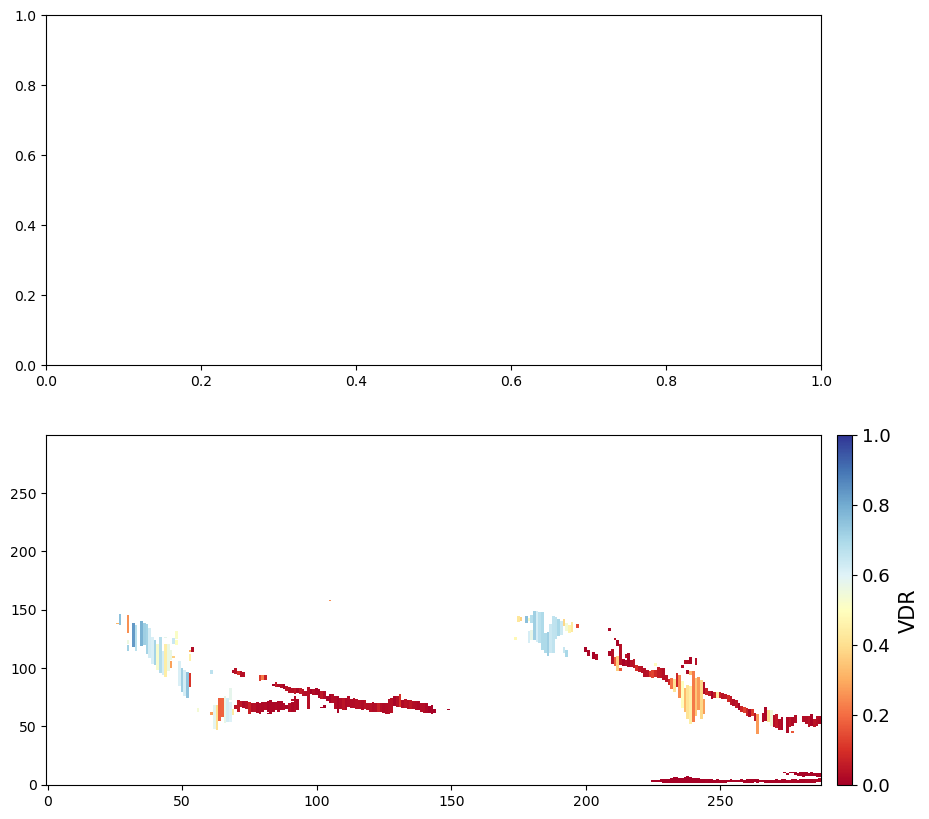

In [14]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(10,10))
ax = axes.ravel()

# Im1 = ax[0].imshow(old['vdr_grouped_mean'].T, aspect='auto', origin='lower', vmin=0,vmax=1, interpolation='None',cmap='RdYlBu')
Im2 = ax[1].imshow(ds['vdr_layer'].T, aspect='auto', origin='lower',vmin=0,vmax=1,interpolation='None',cmap='RdYlBu')



cax2 = ax[1].inset_axes([1.02,0,0.02,1],transform=ax[1].transAxes)

fig.colorbar(Im2,
        extend='neither',
        cax=cax2,
    ).set_label(label='VDR', size=15, labelpad=6)

cax2.tick_params(labelsize=13)